# Module 04 — Media, economics and consumer sentiment
Run top to bottom in a new Colab notebook. No API keys, scoring, or paid requests. Reads the saved Module 01 information sets and Module 03 monthly media export. Outputs go to `04_association_analysis`.

Primary analysis: expanding-window forecasts of headline sentiment using (M1) economics, (M2) economics + news/X negativity, (M3) those predictors + cumulative prices and labor underutilization. Compare all three over identical dates and against the latest sentiment available at the forecast origin. Persistence-augmented versions are important additional benchmarks. Prediction is distinct from causal identification.

Media are retrospective archive measures, not recorded real-time retrievals or respondent exposure. A calendar lag prevents use of future content months, but cannot prove every archived headline was published by the origin. Call forecasts **pseudo-real-time with respect to media**. Human validation remains necessary. No demographic or political controls are invented.

In [1]:
from pathlib import Path
import json, hashlib, sys, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy.stats import t as student_t, norm
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
ROOT=Path('/content/drive/MyDrive/NLP-FinalProject')
SNAPSHOT='2026-10-16'
MEDIA_PATH=ROOT/'03_ai_measurement/headline-measurement-v1/model_runs/4ff1cce4591eb134/media_monthly_for_section4.csv'
ECON_PATH=ROOT/f'01_economic_baseline/processed/{SNAPSHOT}/monthly_information_sets.csv'
OUTCOMES_PATH=ROOT/f'01_economic_baseline/processed/{SNAPSHOT}/survey_forecast_outcomes.csv'
BASE_PRED_PATH=ROOT/f'01_economic_baseline/results/{SNAPSHOT}/out_of_sample_predictions.csv'
# Conservative fixed completed-month endpoint for this submitted snapshot.
LAST_COMPLETE_MONTH='2026-09-01'
MIN_TRAIN=36
HAC_LAGS=3
CORE=['u3','pce_yoy_pct','gdp_qoq_annualized_pct']
CONTROLS=['pce_cumulative_36m_pct','underutilization_gap_pp']
MEDIA=['news_negative_share','x_negative_share']
SETTINGS=dict(snapshot=SNAPSHOT,last_complete_month=LAST_COMPLETE_MONTH,min_train=MIN_TRAIN,
              core=CORE,controls=CONTROLS,media=MEDIA,hac_lags=HAC_LAGS)
for p in [MEDIA_PATH,ECON_PATH,OUTCOMES_PATH,BASE_PRED_PATH]:
    if not p.exists():raise FileNotFoundError(f'Missing saved input: {p}')
HASH=hashlib.sha256(json.dumps(SETTINGS,sort_keys=True).encode()+b''.join(hashlib.sha256(p.read_bytes()).digest() for p in [MEDIA_PATH,ECON_PATH,OUTCOMES_PATH,BASE_PRED_PATH])).hexdigest()[:12]
OUT=ROOT/'04_association_analysis'/f'{SNAPSHOT}_{HASH}'
OUT.mkdir(parents=True,exist_ok=True)
(OUT/'configuration.json').write_text(json.dumps(SETTINGS,indent=2))
print('Outputs:',OUT)

Mounted at /content/drive
Outputs: /content/drive/MyDrive/NLP-FinalProject/04_association_analysis/2026-10-16_c50491e5f4e7


## 1. Join calendar months and preserve release timing
Use first-archived outcomes supplied by Module 01. Training rows must have outcomes available strictly before the current origin. No current revised history is substituted. Quarterly GDP is the latest available quarterly estimate already attached to each monthly information set, without interpolation. Missing media are not zero-filled.

The primary media lag is one full calendar month, with two months as a sensitivity. October 2026 is excluded as an incomplete target/content month for this snapshot. A scheduled future update must explicitly advance the cutoff.

In [2]:
def month_start(values):
    return pd.to_datetime(values,errors='raise',utc=True).dt.tz_convert(None).dt.to_period('M').dt.to_timestamp()
econ=pd.read_csv(ECON_PATH)
outcomes=pd.read_csv(OUTCOMES_PATH)
media=pd.read_csv(MEDIA_PATH)
assert set(CORE+CONTROLS+['observation_month','forecast_origin']).issubset(econ.columns)
assert set(MEDIA+['month']).issubset(media.columns)
outcomes=outcomes.loc[outcomes.target.eq('sentiment')].copy()
for f in [econ,outcomes]:f['month']=month_start(f.observation_month)
media['month']=month_start(media.month)
for name,f in [('economics',econ),('outcomes',outcomes),('media',media)]:
    assert not f.month.duplicated().any(),f'Duplicate months in {name}; inspect release stages rather than arbitrarily choosing one.'
econ['origin']=pd.to_datetime(econ.forecast_origin,utc=True)
outcomes['outcome_available']=pd.to_datetime(outcomes.available_date,utc=True,errors='coerce')
outcomes['actual']=pd.to_numeric(outcomes.value,errors='coerce')
assert outcomes.outcome_available.notna().all(),'Outcome availability is required.'
media=media.set_index('month').sort_index()
media=media.reindex(pd.date_range(media.index.min(),media.index.max(),freq='MS'))
media.index.name='month'
for c in MEDIA:media[c]=pd.to_numeric(media[c],errors='coerce')
lagged=pd.DataFrame(index=media.index)
for lag in [1,2]:
    for c in MEDIA:lagged[f'{c}_lag{lag}']=media[c].shift(lag)
for c in ['news_scoring_completion','x_scoring_completion','news_eligible_items','x_eligible_items','news_eligible_sources']:
    if c in media:lagged[c+'_lag1']=pd.to_numeric(media[c],errors='coerce').shift(1)
data=econ.merge(outcomes[['month','actual','outcome_available']],on='month',how='left',validate='one_to_one').merge(lagged.reset_index(),on='month',how='left',validate='one_to_one')
data=data.loc[data.month.le(pd.Timestamp(LAST_COMPLETE_MONTH))].sort_values('month').reset_index(drop=True)
for c in CORE+CONTROLS:data[c]=pd.to_numeric(data[c],errors='coerce')
# Check recorded predictor availability; date-only archives retain Module 01 limitations.
for c in ['u3_available_date','pce_available_date','gdp_available_date','underutilization_available_date']:
    if c in data:
        dates=pd.to_datetime(data[c],utc=True,errors='coerce')
        assert (dates.isna() | dates.le(data.origin)).all(),f'Future predictor: {c}'
known=outcomes.sort_values(['outcome_available','month'])
data['last_available']=np.nan
for i,row in data.iterrows():
    history=known.loc[known.month.lt(row.month)&known.outcome_available.lt(row.origin)].sort_values('month')
    if len(history):data.loc[i,'last_available']=history.actual.iloc[-1]
data['season_sin']=np.sin(2*np.pi*data.month.dt.month/12)
data['season_cos']=np.cos(2*np.pi*data.month.dt.month/12)
data['trend']=((data.month.dt.year-2010)*12+data.month.dt.month-1)/12
required=CORE+CONTROLS+[c+'_lag1' for c in MEDIA]+['actual','last_available']
data['primary_complete']=data[required].notna().all(axis=1)
data.to_csv(OUT/'merged_monthly_inputs.csv',index=False)
print('Complete common rows:',data.primary_complete.sum())
display(data[['month','actual','last_available','primary_complete']].tail())
display(data[required].isna().sum().rename('missing_rows').to_frame())

Complete common rows: 82


,month,actual,last_available,primary_complete
196,2026-05-01,44.8,49.8,True
197,2026-06-01,49.5,44.8,True
198,2026-07-01,55.2,49.5,True
199,2026-08-01,51.7,49.5,True
200,2026-09-01,NaN,51.7,False


,missing_rows
u3,0
pce_yoy_pct,0
gdp_qoq_annualized_pct,0
pce_cumulative_36m_pct,0
underutilization_gap_pp,15
news_negative_share_lag1,118
x_negative_share_lag1,118
actual,1
last_available,0


## 2. Expanding-window forecasts
Start after 36 eligible training outcomes. Fixed one-month media lag is chosen before seeing results. Annual sine/cosine terms address a parsimonious seasonal pattern; a trend is an explicit sensitivity, not proof that series are stationary. Scaling is estimated on training rows only.

OLS prediction intervals assume a stable linear model and independent errors; treat them as nominal. A second interval uses absolute errors from previous genuinely out-of-sample forecasts (at least 20). Its adaptive empirical coverage is descriptive, not a guaranteed 95% time-series interval. No test outcomes enter model fitting or interval calibration.

In [3]:
SEASON=['season_sin','season_cos']
def specifications(lag=1):
    m=[c+f'_lag{lag}' for c in MEDIA]
    s={'M1_economics':CORE+SEASON,'M2_plus_media':CORE+SEASON+m,'M3_plus_controls':CORE+SEASON+m+CONTROLS}
    s.update({k+'_persistence':v+['last_available'] for k,v in list(s.items())})
    return s

def fit_ols(frame,features,ycol='actual'):
    a=frame[features].to_numpy(float);mu=a.mean(0);sd=a.std(0);sd=np.where(sd>1e-10,sd,1.)
    X=np.column_stack([np.ones(len(a)),(a-mu)/sd]);y=frame[ycol].to_numpy(float)
    if np.linalg.matrix_rank(X)<X.shape[1]:raise ValueError('Rank-deficient training matrix')
    beta=np.linalg.lstsq(X,y,rcond=None)[0];res=y-X@beta;df=len(y)-X.shape[1]
    if df<=0:raise ValueError('Insufficient residual degrees of freedom')
    inv=np.linalg.pinv(X.T@X);s2=float(res@res/df)
    return dict(beta=beta,mu=mu,sd=sd,X=X,res=res,inv=inv,s2=s2,df=df)

def forecast_run(frame,specs,ycol='actual'):
    all_features=sorted(set(sum(list(specs.values()),[])))
    common=frame.dropna(subset=all_features+[ycol,'actual','last_available']).copy()
    rows=[];coefs=[];failures=[];past_errors={name:[] for name in specs}
    for _,row in common.iterrows():
        train=common.loc[common.month.lt(row.month)&common.outcome_available.lt(row.origin)]
        if len(train)<MIN_TRAIN:continue
        pending=[]
        try:
            for name,features in specs.items():
                fit=fit_ols(train,features,ycol)
                x=np.r_[1.,(row[features].to_numpy(float)-fit['mu'])/fit['sd']]
                prediction=float(x@fit['beta'])
                width=float(student_t.ppf(.975,fit['df'])*np.sqrt(fit['s2']*(1+x@fit['inv']@x)))
                offset=float(row.actual-row[ycol]) # zero for levels; latest available for change specification
                absolute_prediction=prediction+offset
                historic=[e for date,e in past_errors[name] if date<row.origin]
                empirical=float(np.quantile(historic,.95)) if len(historic)>=20 else np.nan
                pending.append(dict(month=row.month,origin=row.origin,model=name,n_train=len(train),actual=row.actual,predicted=absolute_prediction,
                    gap=row.actual-absolute_prediction,lower=absolute_prediction-width,upper=absolute_prediction+width,
                    empirical_lower=absolute_prediction-empirical,empirical_upper=absolute_prediction+empirical))
                # Coefficients on original units; media coefficients below are also expressed per 10pp.
                original=fit['beta'][1:]/fit['sd']
                for feature,value in zip(features,original):coefs.append(dict(month=row.month,model=name,feature=feature,coefficient=value))
        except ValueError as exc:
            failures.append(dict(month=row.month,reason=str(exc)));continue
        rows.extend(pending)
        for result in pending:past_errors[result['model']].append((row.outcome_available,abs(result['gap'])))
        rows.append(dict(month=row.month,origin=row.origin,model='last_available',n_train=len(train),actual=row.actual,predicted=row.last_available,gap=row.actual-row.last_available))
    return pd.DataFrame(rows),pd.DataFrame(coefs),pd.DataFrame(failures)

def performance(predictions):
    rows=[]
    for name,g in predictions.groupby('model'):
        r=dict(model=name,n=len(g),rmse=float(np.sqrt(np.mean(g.gap**2))),mae=float(g.gap.abs().mean()),mean_gap=float(g.gap.mean()))
        for label,lo,hi in [('nominal','lower','upper'),('empirical','empirical_lower','empirical_upper')]:
            valid=g.dropna(subset=[lo,hi]) if lo in g else pd.DataFrame()
            r[label+'_n']=len(valid)
            r[label+'_coverage']=valid.actual.between(valid[lo],valid[hi]).mean() if len(valid) else np.nan
        rows.append(r)
    return pd.DataFrame(rows).sort_values('rmse')

forecasts,coefficient_paths,failures=forecast_run(data,specifications())
assert not forecasts.empty,'Too few common months. Inspect missingness before altering MIN_TRAIN.'
summary=performance(forecasts)
forecasts.to_csv(OUT/'rolling_forecasts.csv',index=False)
summary.to_csv(OUT/'forecast_performance.csv',index=False)
coefficient_paths.to_csv(OUT/'rolling_coefficients.csv',index=False)
failures.to_csv(OUT/'forecast_failures.csv',index=False)
display(summary)
print('Common forecast window:',forecasts.month.min(), 'to',forecasts.month.max())

,model,n,rmse,mae,mean_gap,nominal_n,nominal_coverage,empirical_n,empirical_coverage
6,last_available,46,4.595768,3.715217,0.128261,0,NaN,0,NaN
1,M1_economics_persistence,46,5.024128,4.197460,-1.981251,46,0.956522,26,0.923077
3,M2_plus_media_persistence,46,5.081024,4.263209,-2.701726,46,0.978261,26,0.923077
5,M3_plus_controls_persistence,46,5.318723,4.543953,-2.437548,46,0.956522,26,0.884615
4,M3_plus_controls,46,12.112278,9.535369,-8.203414,46,0.695652,26,0.538462
2,M2_plus_media,46,12.620686,10.794248,-10.702891,46,0.804348,26,0.653846
0,M1_economics,46,12.824103,10.767823,-10.679973,46,0.782609,26,0.730769


Common forecast window: 2022-11-01 00:00:00 to 2026-08-01 00:00:00


## 3. Association estimates, dependence and multiple testing
Full-sample coefficients are descriptive associations, not held-out performance or causal effects. Newey–West/Bartlett HAC standard errors use a three-calendar-month bandwidth. Media effects are reported for a 10 percentage-point change. Holm adjustment covers the media-coefficient tests across the displayed primary and persistence-augmented models. Inspect coefficient paths for stability; a small p-value does not establish direction of causation.

HAC treats monthly observations as a time series and does not address measurement error, omitted confounding, nonstationarity, or the uncertainty of estimated media shares. Residual lag-one correlation and Durbin–Watson are diagnostics, not a full dependence correction.

In [4]:
association=[];diagnostics=[]
for name,features in specifications().items():
    frame=data.loc[data.primary_complete].dropna(subset=features+['actual']).sort_values('month')
    fit=fit_ols(frame,features);X=fit['X'];u=fit['res'];Z=X*u[:,None]
    meat=Z.T@Z
    # Calendar-distance matching avoids treating gaps as adjacent months.
    positions={p:i for i,p in enumerate(frame.month.dt.to_period('M'))}
    for lag in range(1,HAC_LAGS+1):
        cross=np.zeros_like(meat)
        for period,i in positions.items():
            j=positions.get(period-lag)
            if j is not None:cross+=np.outer(Z[i],Z[j])
        meat+=(1-lag/(HAC_LAGS+1))*(cross+cross.T)
    cov=fit['inv']@meat@fit['inv']*len(frame)/fit['df']
    se=np.sqrt(np.maximum(np.diag(cov),0))
    for i,feature in enumerate(features,1):
        if feature.startswith(('news_','x_')):
            b=fit['beta'][i]/fit['sd'][i-1];s=se[i]/fit['sd'][i-1]
            association.append(dict(model=name,feature=feature,n=len(frame),effect_per_10pp=b*.1,se_per_10pp=s*.1,
                lower_95=(b-1.96*s)*.1,upper_95=(b+1.96*s)*.1,p_value=float(2*norm.sf(abs(b/s))) if s>0 else np.nan))
    residual=pd.Series(u,index=frame.month.dt.to_period('M')).reindex(pd.period_range(frame.month.min(),frame.month.max(),freq='M'))
    diagnostics.append(dict(model=name,n=len(frame),residual_lag1=residual.corr(residual.shift(1)),
        durbin_watson=float(np.diff(u)@np.diff(u)/(u@u)) if u@u else np.nan,condition_number=float(np.linalg.cond(X))))
assoc=pd.DataFrame(association)
valid=assoc.p_value.dropna().sort_values();m=len(valid);last=0.
for rank,(idx,p) in enumerate(valid.items()):
    last=max(last,min(1.,(m-rank)*p));assoc.loc[idx,'p_holm']=last
assoc.to_csv(OUT/'media_associations_hac.csv',index=False)
pd.DataFrame(diagnostics).to_csv(OUT/'residual_diagnostics.csv',index=False)
display(assoc);display(pd.DataFrame(diagnostics))

,model,feature,n,effect_per_10pp,se_per_10pp,lower_95,upper_95,p_value,p_holm
0,M2_plus_media,news_negative_share_lag1,82,-1.400608,1.901921,-5.128373,2.327157,0.461477,1.000000
1,M2_plus_media,x_negative_share_lag1,82,-3.030109,1.456856,-5.885546,-0.174671,0.037535,0.262745
2,M3_plus_controls,news_negative_share_lag1,82,-0.803922,1.804594,-4.340927,2.733082,0.655968,1.000000
3,M3_plus_controls,x_negative_share_lag1,82,-3.231357,1.439763,-6.053292,-0.409422,0.024809,0.198470
4,M2_plus_media_persistence,news_negative_share_lag1,82,-0.449074,0.713920,-1.848358,0.950210,0.529332,1.000000
5,M2_plus_media_persistence,x_negative_share_lag1,82,-0.917489,0.907629,-2.696443,0.861464,0.312082,1.000000
6,M3_plus_controls_persistence,news_negative_share_lag1,82,-0.472178,0.747912,-1.938085,0.993729,0.527826,1.000000
7,M3_plus_controls_persistence,x_negative_share_lag1,82,-0.851434,0.896859,-2.609278,0.906410,0.342442,1.000000


,model,n,residual_lag1,durbin_watson,condition_number
0,M1_economics,82,0.880725,0.232409,1.966951
1,M2_plus_media,82,0.815314,0.352820,2.286923
2,M3_plus_controls,82,0.769704,0.442985,12.831578
3,M1_economics_persistence,82,0.263463,1.468861,2.136477
4,M2_plus_media_persistence,82,0.192230,1.602556,2.493062
5,M3_plus_controls_persistence,82,0.179426,1.625530,13.765393


## 4. Prespecified sensitivity checks
Two-month media lag; linear trend; exclude pandemic target months from scoring (not training); changes relative to last available sentiment; and higher-completion content months. These are robustness checks, not a contest to select the best result after looking at performance. Each variant compares models on its own common months; also report a strict intersection of primary and alternative dates. Two-month media lag is not a real-time archive guarantee.

A warning-free and unclear-geography sensitivity requires regenerating Module 03 media aggregates; the supplied monthly export cannot reconstruct those alternatives. Do not claim they were run.

In [5]:
sensitivity=[]
variants={
    'lag2':(data.copy(),specifications(2),'actual'),
    'with_trend':(data.copy(),{k:v+['trend'] for k,v in specifications().items()},'actual'),
    'change_from_last_available':(data.assign(change=data.actual-data.last_available),specifications(),'change')
}
quality=['news_scoring_completion_lag1','x_scoring_completion_lag1']
if set(quality).issubset(data):
    variants['completion_at_least_80pct']=(data.loc[data[quality].ge(.8).all(axis=1)].copy(),specifications(),'actual')
variant_predictions={'primary':forecasts}
for label,(frame,specs,target) in variants.items():
    fp,_,_=forecast_run(frame,specs,target)
    if fp.empty:print('No forecasts for:',label);continue
    variant_predictions[label]=fp
    tab=performance(fp);tab.insert(0,'variant',label);sensitivity.append(tab)
    fp.to_csv(OUT/f'forecasts_{label}.csv',index=False)
nonpandemic=forecasts.loc[~forecasts.month.between('2020-03-01','2021-12-01')]
if len(nonpandemic):
    tab=performance(nonpandemic);tab.insert(0,'variant','exclude_pandemic_evaluation_only');sensitivity.append(tab)
sensitivity_table=pd.concat(sensitivity,ignore_index=True) if sensitivity else pd.DataFrame()
sensitivity_table.to_csv(OUT/'sensitivity_performance.csv',index=False)
display(sensitivity_table)
shared=set.intersection(*(set(f.month) for f in variant_predictions.values()))
strict=[]
for label,fp in variant_predictions.items():
    if shared:
        tab=performance(fp.loc[fp.month.isin(shared)]);tab.insert(0,'variant',label);strict.append(tab)
strict_table=pd.concat(strict,ignore_index=True) if strict else pd.DataFrame()
strict_table.to_csv(OUT/'sensitivity_common_dates.csv',index=False)
print('Strict common sensitivity months:',len(shared))

,variant,model,n,rmse,mae,mean_gap,nominal_n,nominal_coverage,empirical_n,empirical_coverage
0,lag2,last_available,45,4.623515,3.728889,0.200000,0,NaN,0,NaN
1,lag2,M1_economics_persistence,45,5.028157,4.164050,-1.916357,45,0.955556,25,0.920000
2,lag2,M2_plus_media_persistence,45,5.165221,4.270248,-2.190759,45,0.955556,25,0.920000
3,lag2,M3_plus_controls_persistence,45,5.420500,4.518253,-1.923027,45,0.955556,25,0.920000
4,lag2,M3_plus_controls,45,12.120492,9.648947,-7.931339,45,0.777778,25,0.680000
5,lag2,M2_plus_media,45,12.274251,10.256315,-10.012190,45,0.844444,25,0.840000
6,lag2,M1_economics,45,12.525197,10.413210,-10.304305,45,0.800000,25,0.720000
7,with_trend,M3_plus_controls_persistence,46,4.303556,3.481193,0.642958,46,0.978261,26,0.923077
8,with_trend,last_available,46,4.595768,3.715217,0.128261,0,NaN,0,NaN
9,with_trend,M2_plus_media_persistence,46,4.612936,3.945847,-0.884491,46,1.000000,26,0.961538


Strict common sensitivity months: 30


## 5. Sentiment-gap analysis and plots
The Module 01 economic-core gap is observed sentiment minus an out-of-sample economic prediction. A regression of that gap is a descriptive second-stage association: the baseline forecast is estimated, and its uncertainty is not fully propagated. Direct sentiment forecasts above remain the primary comparison. Negative residuals are not proof of bias.

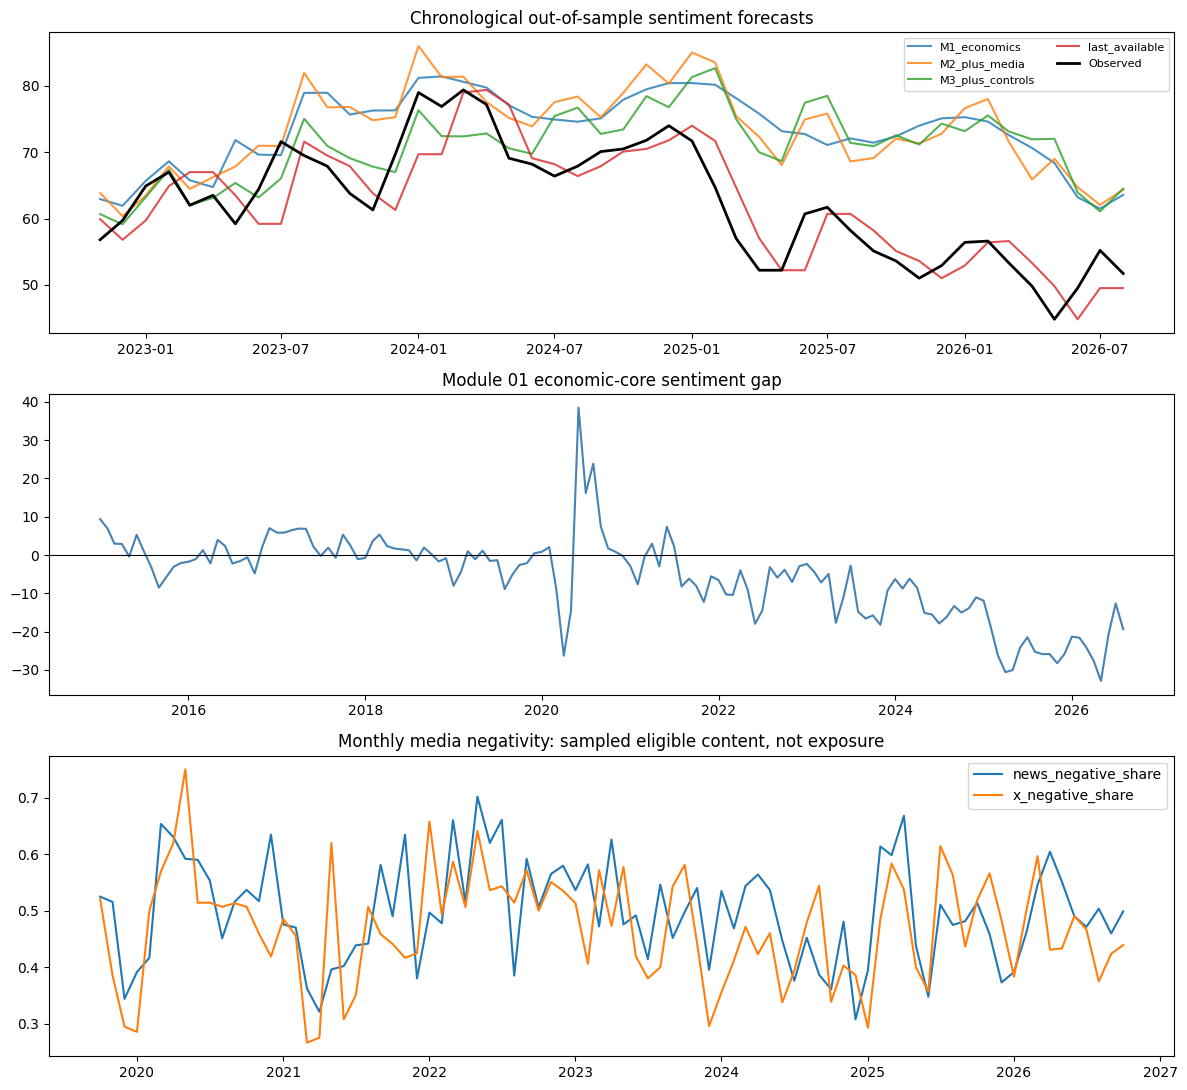

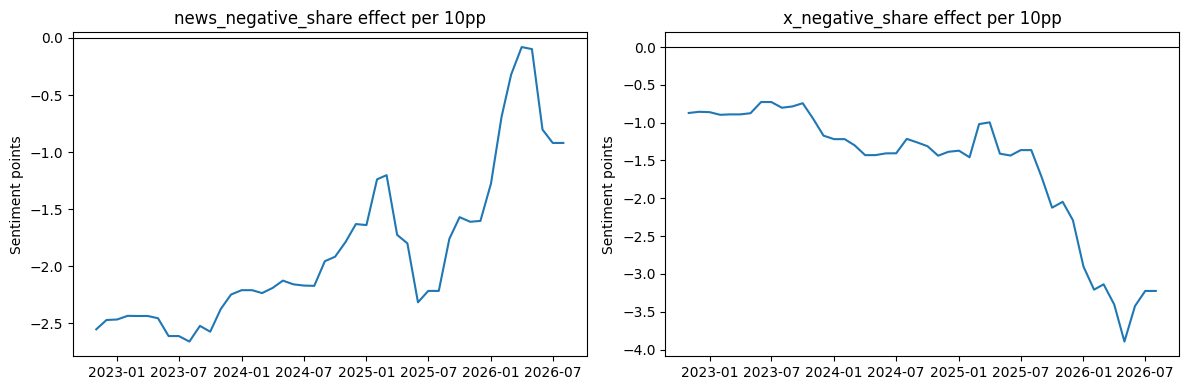

Outputs ready: /content/drive/MyDrive/NLP-FinalProject/04_association_analysis/2026-10-16_c50491e5f4e7
Send forecast_performance.csv and media_associations_hac.csv for interpretation.


In [6]:
base=pd.read_csv(BASE_PRED_PATH)
base=base.loc[base.target.eq('sentiment')&base.model.eq('economic_core')].copy()
base['month']=month_start(base.observation_month)
assert not base.month.duplicated().any()
gap_data=data.merge(base[['month','sentiment_gap']],on='month',how='left',validate='one_to_one')
gap_data.to_csv(OUT/'sentiment_gap_with_media.csv',index=False)
fig,axes=plt.subplots(3,1,figsize=(12,11))
for name in ['M1_economics','M2_plus_media','M3_plus_controls','last_available']:
    f=forecasts.loc[forecasts.model.eq(name)]
    axes[0].plot(f.month,f.predicted,label=name,alpha=.8)
actual=forecasts.drop_duplicates('month').sort_values('month')
axes[0].plot(actual.month,actual.actual,color='black',label='Observed',lw=2)
axes[0].set_title('Chronological out-of-sample sentiment forecasts');axes[0].legend(fontsize=8,ncol=2)
axes[1].plot(gap_data.month,gap_data.sentiment_gap,color='steelblue');axes[1].axhline(0,color='black',lw=.8)
axes[1].set_title('Module 01 economic-core sentiment gap')
for c in MEDIA:axes[2].plot(media.index,media[c],label=c)
axes[2].set_title('Monthly media negativity: sampled eligible content, not exposure');axes[2].legend()
fig.tight_layout();fig.savefig(OUT/'section4_overview.png',dpi=180);plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,c in zip(axes,MEDIA):
    selected=coefficient_paths.loc[coefficient_paths.model.eq('M3_plus_controls')&coefficient_paths.feature.eq(c+'_lag1')]
    ax.plot(selected.month,selected.coefficient*.1);ax.axhline(0,color='black',lw=.8)
    ax.set_title(c+' effect per 10pp');ax.set_ylabel('Sentiment points')
fig.tight_layout();fig.savefig(OUT/'media_coefficient_stability.png',dpi=180);plt.show()
print('Outputs ready:',OUT)
print('Send forecast_performance.csv and media_associations_hac.csv for interpretation.')

## 6. Causal-design proposal and limits for the report
**Design chosen: observational associations plus a prospective randomized framing experiment.** No causal effect is estimated by this notebook.

Recruit consenting adults; use identical official numerical facts and randomly assign a price-level framing versus an inflation-rate framing, with a balanced factual reference arm. Pre-register recruitment, sample size/power, outcomes, exclusion rules, assignment and analysis before collection. Measure pre/post economic beliefs, factual comprehension, recall and sentiment-related responses. Primary estimand: intention-to-treat difference in the predeclared response, adjusted for its baseline value; report confidence intervals and multiplicity-adjusted secondary tests. Do not field the experiment without the required course/institutional review and consent procedure.

Collect baseline political affiliation, income, age, geography and media habits; prespecify limited moderator tests. Randomization supports within-sample identification if assignment is implemented correctly, attrition is handled transparently and spillovers are limited. Assess differential attrition, manipulation comprehension and treatment contamination without conditioning the primary effect on post-treatment compliance.

Observational results remain subject to reverse causality (pessimistic audiences seek negative content and publishers respond), common economic shocks, political confounding, measurement error and changing source composition. Lagging media does not eliminate these problems. The outcome series can also be affected by survey-method changes; add a documented methodology sensitivity only after verifying transition dates, rather than guessing a break date.

An experimental response in a convenience sample would not establish an effect on the national Michigan index. That requires representative recruitment or defensible transport weights, population exposure and treatment-intensity estimates, comparable outcome measurement, and explicit assumptions about heterogeneous effects and spillovers. The dashboard should display these limitations, missingness, scoring coverage and the snapshot cutoff.

**Submission checks:** report human validation as completed only when available; include 2,560 unresolved items as a limitation; source-label testing does not substitute for political-name testing; factual calibration remains unassessed. Do not claim that changing predictive accuracy establishes media causation or that a sentiment gap proves cognitive bias.

In [ ]:
import importlib.metadata as metadata
versions={}
for name in ['numpy','pandas','scipy','matplotlib']:
    try:versions[name]=metadata.version(name)
    except metadata.PackageNotFoundError:versions[name]='unknown'
(OUT/'environment.json').write_text(json.dumps(dict(python=sys.version,packages=versions,created_utc=datetime.now(timezone.utc).isoformat()),indent=2))
print('Complete. No scoring or external API calls were made.')